# The Trading Desk That Sees Contagion Before Prices Do
## Market intelligence through an institutional Second Brain

**Second Brain: Engineering Context for Intelligent Decisions**  
**Laboratory 2 of 4 · Market contagion · Exactly 10 executable code cells**

> **Research question.** Can a provenance-aware institutional knowledge graph detect economically meaningful contagion pathways after a supply-chain shock and deliver an evidence-grounded trading-desk memorandum that would not be apparent from historical return correlations alone?

**Scope.** This is a fully synthetic pedagogical simulation. The companies, links, shocks, prices, and portfolio positions are invented. No output constitutes investment advice, a prediction of market performance, or a real-world claim about particular firms.

**Execution.** Google Colab or Python 3.10+. Claude Haiku 5.5 is optional and requires the Colab Secret `ANTHROPIC_API_KEY`. The ten cells construct a 500-company universe, represent relationships as Obsidian notes and typed edges, propagate a semiconductor shock, compare retrieval and market baselines, invoke bounded model judgment if available, and export all evidence.

---

## Introduction — Institutional knowledge meets market intelligence

Financial markets are often analyzed by looking first at market prices. Returns, volatilities, correlations and estimated factors provide an indispensable language for risk. Yet a trading desk confronted with a new disturbance faces a different question: which firms are structurally exposed before the historical return series has enough observations to register the new transmission mechanism? A factory outage can interrupt an input, which delays a component, which constrains an assembler, which weakens a borrower, which affects a lender. These dependencies are economic facts and organizational knowledge before they become statistical regularities.

This laboratory makes that distinction operational. The universe contains five hundred synthetic companies and multiple networks: supplier–buyer dependencies, common financing channels, equity ownership, sector affinity, and geographic concentration. Each relationship is given a type and a direction. The result is not merely a graph of who knows whom. It is a record of how disturbances may travel and of why a particular edge should matter for a specified event. Although the data are invented, the analytical challenge resembles the work of investment committees, risk offices, supply-chain analysts, and financial supervisors.

The starting point is the Second Brain conception developed in Laboratory 01. External institutional memory stores durable notes. Metadata preserves identifiers and provenance. A typed knowledge graph captures dependencies. Deterministic tools calculate and constrain. A large language model receives selected evidence, distinguishes what is known from what is conjectured, and prepares a compact, reviewable recommendation. Governance and export make the chain reproducible. The move from regulation to market intelligence is deliberate: it tests whether the same architecture generalizes across a domain boundary while respecting the specific semantics of financial dependencies.

The case begins with a hypothetical disruption at selected semiconductor manufacturers in East Asia. We introduce direct production impairment and let its effects pass through supplier–customer edges with diminishing intensity. We separately consider shared lenders and ownership networks as channels for second-round vulnerability. Not every network connection is causally equivalent. A supply edge may transmit operational scarcity; common ownership may transmit portfolio-level concentration but not a physical production stoppage. The program therefore records edge types and explicitly weights them, instead of collapsing every link into a generic relevance score.

The laboratory teaches an important form of disciplined imagination. Traditional covariance matrices summarize co-movement during the estimation window. They are useful for portfolio construction, but they do not encode all possible future operational linkages. A company can be a major indirect customer of a disrupted input even if its historical returns were weakly correlated with the initial supplier. Conversely, a high-correlation peer might have no meaningful direct dependence on the affected component. Our objective is not to demonstrate that correlations are useless; it is to isolate their informational limits during a genuinely new structural shock.

The second major teaching point concerns the difference between retrieval and navigation. A lexical or TF–IDF search can locate notes mentioning semiconductors. An event-conditioned graph traversal can follow a supplier into an assembler and then into a financed distributor, assembling a chain of evidence even if the final firm’s note never contains the term semiconductor. This is the knowledge advantage of relational context. It is also a liability when edges are wrong, stale, weakly substantiated, or excessively permissive. We therefore retain edge provenance, maintain bounded traversal, and make graph-generated claims inspectable.

The exercise intentionally separates three operations often confused in discussions of AI. First, an economic model computes deterministic exposure indicators under transparent simplifying assumptions. Second, an information architecture selects and packages the evidence used to discuss those indicators. Third, Claude Haiku 5.5, when authorized and available, proposes judgment under explicit restrictions. The model does not manufacture market observations, run trades, or silently rewrite the graph. Its task is to articulate plausible risk responses, limitations and monitoring triggers from the context supplied by the preceding cells.

Four experimental conditions support comparison. An event-only baseline knows the shock narrative but not the dependency structure. A broad-document context concatenates a bounded sample of company notes. A TF–IDF context retrieves firms using word overlap. A graph-aware context follows typed dependencies and preserves the exposure calculation with source identifiers. Because the contexts carry different information and lengths, the experiment is an architectural demonstration rather than a controlled estimate of causal performance. We make this caveat explicit when interpreting recall, evidence efficiency, and any generated memorandum.

The synthetic portfolio includes representative positions, allowing us to connect knowledge retrieval to a practical risk-management question. A sensible output does not need to say “buy” or “sell.” It may recommend deeper counterparty review, temporary concentration limits, scenario hedges, or additional data collection. A genuine institutional decision also requires liquidity, execution costs, mandates, compliance, and human authorization, none of which this simplified exercise fully models. The notebook therefore yields a decision-support memorandum, not autonomous trading instructions.

Finally, the laboratory addresses institutional memory as a process rather than a static archive. The system exports Markdown notes, the relationship ledger, the event definition, the propagation results, retrieved context packages, evaluation tables and the optional model response. Each item can be reloaded and challenged. Students can change the disrupted manufacturers, weaken a transmission parameter, delete an edge, or add a financing concentration, then compare how the evidence and recommendation change. These controlled counterfactuals are the bridge from passive corporate knowledge to intelligence capable of supporting accountable action.

The essential lesson is that prices are not the only data in finance. Relationships, contracts, physical dependencies and institutional experience form an additional informational layer. When that layer is governed, searchable and connected to bounded reasoning, it can create earlier and more explainable hypotheses about vulnerability. Whether those hypotheses are correct remains an empirical question. A Second Brain improves the discipline with which the question can be investigated; it does not guarantee foresight.

## Cell 01 — Environment, reproducibility, and secrets

We begin by fixing the computational conditions under which the experiment can be repeated. A trading desk cannot audit a result when random draws, package versions or model parameters are implicit. We therefore seed the synthetic data generator and create an explicit project directory. The secret used to access Claude is optional: all purely deterministic stages must work without a paid API or model access. This preserves a clean boundary between evidence construction and the judgment engine.

A second consideration is the difference between demonstrative and deployable code. The notebook is deliberately accessible to financial practitioners who may not write software professionally. However, accessibility must not mean hiding dependencies or swallowing errors. The setup cell checks its environment, installs only absent libraries, and records whether a model key was found without printing its value. No external market feeds are contacted and no actual order submission capability exists.

The resulting working directory functions as an evidence workspace. Later cells will write a Markdown vault and serialized tables into it; the final cell will make a reproducible archive. In a live institutional setting this workspace would be subject to identity controls, information classification, retention rules and quality review. For our teaching example, transparent local files are a better starting point than an opaque service. The central lesson is that an institutional Second Brain begins with disciplined recordkeeping, not with a chatbot interface.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# @title
import os, sys, subprocess, importlib.util, json, random, pathlib
for package, module in [('numpy','numpy'),('pandas','pandas'),('networkx','networkx'),('scikit-learn','sklearn'),('matplotlib','matplotlib')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','-q','install',package])
import numpy as np, pandas as pd, networkx as nx
from IPython.display import display
SEED=791; random.seed(SEED); np.random.seed(SEED)
ROOT=pathlib.Path('/content/drive/MyDrive/Colab Notebooks/TOPIC_792 SECOND BRAIN MARKET CONTAGION')
ROOT.mkdir(parents=True,exist_ok=True)
try:
    from google.colab import userdata
    API_KEY=userdata.get('ANTHROPIC_API_KEY')
except Exception:
    API_KEY=os.environ.get('ANTHROPIC_API_KEY')
MODEL='claude-haiku-5-5'
print('Workspace:',ROOT,'| Claude key available:',bool(API_KEY),'| Seed:',SEED)

Workspace: /content/drive/MyDrive/Colab Notebooks/TOPIC_792 SECOND BRAIN MARKET CONTAGION | Claude key available: True | Seed: 791


## Cell 02 — Build the 500-company institutional universe

The second stage creates a controlled universe large enough to exhibit nontrivial network behavior but small enough to inspect. Each company receives a stable identifier, a sector, a region, a descriptive business activity and simple synthetic financial indicators. These attributes are not forecasts or observations. They are pedagogical scaffolding that lets us ask which exposures are direct, which are indirect and which arise from concentration rather than operational dependency.

The corporate population includes manufacturers of semiconductors, components, devices and industrial products as well as distributors, transport firms, retailers, banks and software companies. Its heterogeneity is important. A purely homogeneous network might make graph traversal look impressive while offering few meaningful distinctions. Here a disruption in semiconductor output should have a stronger immediate impact on companies sourcing chips than on a financial intermediary with no direct operating dependence. The latter might nevertheless be exposed through lending or investment positions.

To emphasize reproducibility, the cell constructs the population using a fixed seed. The variables are intuitive rather than optimized: simplified revenue, leverage and cash-buffer proxies make the subsequent risk score easy to teach. These values should not be mistaken for actual firm balance sheets or a calibrated contagion model. We reserve definitive empirical claims for a future version with authenticated issuer, supply-chain and market data. The outcome of this cell is a machine-readable corporate registry, which becomes the first layer of institutional memory.

In [ ]:
# @title
SECTORS=['Semiconductors','Components','Electronics','Automotive','Industrials','Logistics','Retail','Banks','Software','Utilities']
REGIONS=['East Asia','North America','Europe','Latin America','South Asia']
rng=np.random.default_rng(SEED)
rows=[]
for i in range(500):
    sector=SECTORS[i%len(SECTORS)]; region=REGIONS[(i//10+i)%len(REGIONS)]
    rows.append({'id':f'CO_{i+1:03d}','name':f'Synthetic {sector[:-1] if sector.endswith("s") else sector} Holdings {i+1:03d}',
      'sector':sector,'region':region,'revenue_musd':round(float(rng.lognormal(5.2,.75)),2),
      'leverage':round(float(rng.uniform(.1,.85)),3),'cash_buffer':round(float(rng.uniform(.15,.95)),3),
      'description':f'{sector} company operating primarily in {region}; synthetic educational entity.'})
companies=pd.DataFrame(rows).set_index('id',drop=False)
assert len(companies)==500 and companies.id.is_unique
companies.to_csv(ROOT/'companies.csv',index=False)
print(companies.groupby('sector').size().to_string()); display(companies.head(5))

sector
Automotive        50
Banks             50
Components        50
Electronics       50
Industrials       50
Logistics         50
Retail            50
Semiconductors    50
Software          50
Utilities         50


,id,name,sector,region,revenue_musd,leverage,cash_buffer,description
id,,,,,,,,
CO_001,CO_001,Synthetic Semiconductor Holdings 001,Semiconductors,East Asia,148.00,0.326,0.353,Semiconductors company operating primarily in ...
CO_002,CO_002,Synthetic Component Holdings 002,Components,North America,226.20,0.243,0.315,Components company operating primarily in Nort...
CO_003,CO_003,Synthetic Electronic Holdings 003,Electronics,Europe,86.47,0.297,0.419,Electronics company operating primarily in Eur...
CO_004,CO_004,Synthetic Automotive Holdings 004,Automotive,Latin America,482.07,0.689,0.907,Automotive company operating primarily in Lati...
CO_005,CO_005,Synthetic Industrial Holdings 005,Industrials,South Asia,125.58,0.282,0.300,Industrials company operating primarily in Sou...


## Cell 03 — Build relationship records and an Obsidian vault

A list of companies is not yet a Second Brain. Intelligence begins when the records capture how companies depend on one another. This stage creates several directed and typed link families. The direction of a supply edge runs from supplier to customer, matching the direction in which a shortage might propagate. A financing edge runs from lender to borrower and signals a possible credit exposure. An ownership edge records a synthetic investor-to-investee relation and is deliberately treated differently from the physical supply network.

Each link receives a source ID, confidence and effective-date interval. These features are modest stand-ins for a richer provenance system. They let a student inspect why a connection exists, whether it is current for the simulated event date and whether it should be regarded as certain. The vault also receives one Markdown note per company, with YAML-style frontmatter and Obsidian-compatible wikilinks. The notes are readable without Python, which matters if analysts or compliance teams later need to challenge the source material.

We intentionally generate the link ledger and the notes from one common canonical record, reducing the chance that the display and the graph disagree. In a real environment, one would additionally require source-specific permissions, version snapshots, supplier attestations and procedures for managing disputes. For the present laboratory, the most important discipline is simple: economic claims must point to durable records rather than appearing as untraceable statements in a model response.

In [ ]:
# @title

# ============================================================
# CELL 03 — RELATIONSHIP LEDGER AND RICH OBSIDIAN VAULT
# LAB 02 — MARKET CONTAGION SECOND BRAIN
#
# COMPLETE REPAIRED VERSION
#
# - Preserves the original synthetic relationship logic
# - Generates 500 rich Markdown company dossiers
# - Includes incoming and outgoing relationships
# - Preserves evidence IDs and downstream compatibility
# - Adds Google Drive I/O retries and verification
# - Validates the completed institutional vault
# ============================================================

import time
import json
import pandas as pd
from pathlib import Path
from collections import defaultdict

# ------------------------------------------------------------
# 1. VERIFY ENVIRONMENT
# ------------------------------------------------------------

assert len(companies) == 500, (
    "Cell 02 must create exactly 500 companies."
)

assert companies.index.is_unique, (
    "Company identifiers must be unique."
)

ROOT = Path(ROOT)

VAULT = ROOT / "Vault"
NOTES = VAULT / "Notes"

NOTES.mkdir(parents=True, exist_ok=True)

print("=" * 68)
print("CELL 03 — BUILDING THE INSTITUTIONAL SECOND BRAIN")
print("=" * 68)

print("Working directory:", ROOT)
print("Obsidian notes:", NOTES)


# ------------------------------------------------------------
# 2. RESILIENT FILE-WRITING FUNCTION
# ------------------------------------------------------------

MAX_ATTEMPTS = 5

def safe_write_text(path, content, attempts=MAX_ATTEMPTS):
    """
    Write a UTF-8 text file with retries and verification.

    Designed to tolerate intermittent Google Drive
    filesystem interruptions in Google Colab.

    Uses exponential backoff and verifies the
    expected file size after writing.
    """

    path = Path(path)
    expected_size = len(content.encode("utf-8"))

    for attempt in range(attempts):

        try:

            path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            path.write_text(
                content,
                encoding="utf-8"
            )

            actual_size = path.stat().st_size

            if actual_size != expected_size:
                raise OSError(
                    f"Incomplete write: {path.name}; "
                    f"expected={expected_size}, "
                    f"actual={actual_size}"
                )

            return True

        except OSError as exc:

            print(
                f"Write issue: {path.name} | "
                f"Attempt {attempt + 1}/{attempts} | "
                f"{type(exc).__name__}: {exc}"
            )

            if attempt == attempts - 1:
                raise RuntimeError(
                    f"Unable to save {path.name} "
                    f"after {attempts} attempts."
                ) from exc

            delay = 2 ** attempt

            print(f"Retrying in {delay} seconds...")
            time.sleep(delay)

    return False


# ------------------------------------------------------------
# 3. GENERATE THE SYNTHETIC RELATIONSHIP LEDGER
# ------------------------------------------------------------

edges = []

def add(src, dst, relation, weight, seq):

    if src == dst:
        return

    edges.append({
        "source": src,
        "target": dst,
        "relation": relation,
        "weight": round(float(weight), 3),
        "evidence_id": f"EDGE_{seq:05d}",
        "provenance": "SYNTHETIC_GENERATOR_791",
        "confidence": round(
            float(rng.uniform(.78, .99)), 3
        ),
        "valid_from": "2026-01-01",
        "valid_to": "2027-12-31"
    })


ids = list(companies.index)
k = 0

# Preserve the original random-number generator
# and the original relationship-generation logic.

for customer in ids:

    sector = companies.loc[customer, "sector"]

    # Number of upstream suppliers
    supply_n = (
        3 if sector in [
            "Components",
            "Electronics",
            "Automotive",
            "Industrials"
        ] else 2
    )

    # Supplier eligibility rules
    if sector in [
        "Components",
        "Electronics",
        "Automotive"
    ]:
        eligible_sectors = [
            "Semiconductors",
            "Components"
        ]
    else:
        eligible_sectors = SECTORS[:7]

    candidates = [
        x for x in ids
        if x != customer
        and companies.loc[x, "sector"]
        in eligible_sectors
    ]

    # Generate supply-chain relationships
    for upstream in rng.choice(
        candidates,
        size=supply_n,
        replace=False
    ):

        k += 1

        add(
            str(upstream),
            customer,
            "supplies",
            rng.uniform(.15, .75),
            k
        )

    # Generate financing relationships
    if sector != "Banks":

        lenders = [
            x for x in ids
            if companies.loc[x, "sector"] == "Banks"
        ]

        lender = str(rng.choice(lenders))

        k += 1

        add(
            lender,
            customer,
            "finances",
            rng.uniform(.08, .4),
            k
        )

    # Generate equity ownership relationships
    if rng.random() < .33:

        possible_owners = [
            x for x in ids if x != customer
        ]

        owner = str(rng.choice(possible_owners))

        k += 1

        add(
            owner,
            customer,
            "owns_stake_in",
            rng.uniform(.05, .3),
            k
        )


relationships = (
    pd.DataFrame(edges)
    .drop_duplicates(
        ["source", "target", "relation"]
    )
    .reset_index(drop=True)
)

print("\nRelationship generation completed.")
print("Total relationships:", len(relationships))

print("\nRelationships by type:")
print(
    relationships["relation"]
    .value_counts()
    .to_string()
)


# ------------------------------------------------------------
# 4. VALIDATE AND SAVE THE RELATIONSHIP LEDGER
# ------------------------------------------------------------

assert relationships.evidence_id.is_unique

assert relationships.weight.between(0, 1).all()

assert set(relationships.source).issubset(
    set(ids)
)

assert set(relationships.target).issubset(
    set(ids)
)

ledger_path = ROOT / "relationship_ledger.csv"

safe_write_text(
    ledger_path,
    relationships.to_csv(index=False)
)

print("\nRelationship ledger saved:")
print(ledger_path)


# ------------------------------------------------------------
# 5. INDEX ALL INCOMING AND OUTGOING RELATIONSHIPS
# ------------------------------------------------------------

by_source = defaultdict(list)
by_target = defaultdict(list)

for e in relationships.itertuples(index=False):

    by_source[e.source].append(e)
    by_target[e.target].append(e)


# ------------------------------------------------------------
# 6. FORMAT EVIDENCE-LINKED OBSIDIAN RELATIONSHIPS
# ------------------------------------------------------------

def format_relationships(records, direction):

    if not records:
        return (
            "_No relationships recorded "
            "in this direction._"
        )

    lines = []

    for e in sorted(
        records,
        key=lambda x: (
            x.relation,
            x.evidence_id
        )
    ):

        counterparty = (
            e.target
            if direction == "outgoing"
            else e.source
        )

        lines.append(
            f"- [[{counterparty}]] "
            f"| Type: {e.relation} "
            f"| Weight: {e.weight:.3f} "
            f"| Confidence: {e.confidence:.3f} "
            f"| Evidence: {e.evidence_id} "
            f"| Valid: {e.valid_from} "
            f"to {e.valid_to}"
        )

    return "\n".join(lines)


# ------------------------------------------------------------
# 7. GENERATE ALL 500 RICH COMPANY DOSSIERS
# ------------------------------------------------------------

print("\nGenerating detailed company dossiers...")

completed = 0

for r in companies.itertuples(index=False):

    inbound = by_target[r.id]
    outbound = by_source[r.id]

    suppliers = [
        e for e in inbound
        if e.relation == "supplies"
    ]

    customers = [
        e for e in outbound
        if e.relation == "supplies"
    ]

    lenders = [
        e for e in inbound
        if e.relation == "finances"
    ]

    borrowers = [
        e for e in outbound
        if e.relation == "finances"
    ]

    shareholders = [
        e for e in inbound
        if e.relation == "owns_stake_in"
    ]

    equity_positions = [
        e for e in outbound
        if e.relation == "owns_stake_in"
    ]

    total_in = len(inbound)
    total_out = len(outbound)

    total_connections = total_in + total_out

    # Construct the complete Markdown dossier.

    content = f"""---
id: {r.id}
type: company
sector: {r.sector}
region: {r.region}
provenance: SYNTHETIC_GENERATOR_791
status: synthetic
---

# {r.name}

## 1. Company Identification

**Company ID:** {r.id}

**Name:** {r.name}

**Sector:** {r.sector}

**Region:** {r.region}

**Entity type:** Synthetic educational corporation

### Business Description

{r.description}

This company belongs to a fictional institutional
network designed to examine supply-chain
dependencies, financial contagion, and the
retrieval of interconnected corporate knowledge.

The entity does not represent a real corporation.


## 2. Financial Characteristics

| Variable | Synthetic Value |
|---|---:|
| Revenue (USD millions) | {r.revenue_musd:,.2f} |
| Leverage indicator | {r.leverage:.3f} |
| Cash-buffer indicator | {r.cash_buffer:.3f} |

### Financial Interpretation

Revenue represents simulated company scale.

The leverage indicator is a synthetic variable
that may influence simulated financial vulnerability.

The cash-buffer indicator is a synthetic measure
of financial resilience.

These values are model inputs and are not
audited financial statements.


## 3. Position in the Corporate Network

| Network Indicator | Count |
|---|---:|
| Incoming relationships | {total_in} |
| Outgoing relationships | {total_out} |
| Total directed connections | {total_connections} |
| Recorded suppliers | {len(suppliers)} |
| Recorded customers | {len(customers)} |
| Recorded lenders | {len(lenders)} |
| Recorded borrowers | {len(borrowers)} |
| Recorded shareholders | {len(shareholders)} |
| Recorded equity positions | {len(equity_positions)} |

These indicators describe this company's direct
position within the synthetic corporate network.

Connectivity alone does not establish systemic
importance or economic vulnerability.


## 4. Supply-Chain Dependencies

### 4.1 Upstream Suppliers

These entities provide inputs to this company.

{format_relationships(suppliers, "incoming")}

### 4.2 Downstream Customers

These entities receive inputs from this company.

{format_relationships(customers, "outgoing")}


## 5. Financing Relationships

### 5.1 Lenders to This Company

{format_relationships(lenders, "incoming")}

### 5.2 Borrowers Financed by This Company

{format_relationships(borrowers, "outgoing")}


## 6. Equity Ownership Relationships

### 6.1 Shareholders of This Company

{format_relationships(shareholders, "incoming")}

### 6.2 Equity Interests Held by This Company

{format_relationships(equity_positions, "outgoing")}


## 7. Complete Relationship Inventory

### 7.1 All Incoming Relationships

{format_relationships(inbound, "incoming")}

### 7.2 All Outgoing Relationships

{format_relationships(outbound, "outgoing")}


## 8. Contagion and Risk Interpretation

The company participates in a directed corporate
knowledge graph containing three economic
relationship categories.

### Supply-Chain Transmission

A production disruption affecting an upstream
supplier may propagate to downstream customers.

The direction of a supply edge is:

Supplier -> Customer

The extent of transmission depends on the
synthetic propagation model, relationship weights,
and propagation decay assumptions.

### Financing Relationships

Financing relationships describe synthetic
credit connections between lenders and borrowers.

They provide institutional context but are not
automatically included in the operational
supply-shock propagation algorithm.

### Ownership Relationships

Equity ownership relationships provide
additional information on simulated corporate
cross-investment and possible economic linkages.

Ownership relationships are not automatically
treated as channels of operational contagion.

### Exposure Measurement

The company-specific operational exposure
and risk indicator are calculated separately
by Cell 05 of this laboratory.

The existence of a relationship does not
establish the magnitude of a transmitted shock.


## 9. Evidence and Provenance

**Source:** SYNTHETIC_GENERATOR_791

**Canonical company registry:** companies.csv

**Canonical relationship ledger:**
relationship_ledger.csv

Each relationship contains:

- Source company identifier
- Target company identifier
- Relationship type
- Synthetic relationship weight
- Unique evidence identifier
- Synthetic confidence indicator
- Beginning of validity interval
- End of validity interval

The evidence identifier allows an analytical
system to trace a proposed transmission
path to its constituent relationship records.

All source records are fictional.


## 10. Knowledge-Graph Usage

This document is an Obsidian-compatible
institutional knowledge node.

References such as [[CO_001]] permit navigation
between company dossiers.

The complete relationship ledger supports
computational graph traversal.

Graph algorithms can identify connected
entities and evaluate synthetic propagation
pathways.

A language model can subsequently interpret
retrieved evidence and explain potential
institutional implications.

The language model must distinguish factual
synthetic inputs from its own inferences.

Final financial decisions remain subject
to human judgment and institutional governance.


## 11. Methodological Limitations

- All companies are fictional.
- All relationships are synthetic.
- Financial characteristics are simulated.
- Network weights are not empirical exposures.
- Confidence parameters are synthetic.
- Network connectivity does not prove causality.
- Operational stress indicators are not
  probabilities or financial forecasts.
- Model-generated interpretations require review.
- The exercise does not constitute trading advice.

This dossier is intended exclusively for
research and educational purposes.
"""

    # --------------------------------------------------------
    # RESILIENT GOOGLE DRIVE WRITE
    # --------------------------------------------------------

    path = NOTES / f"{r.id}.md"

    safe_write_text(
        path,
        content
    )

    completed += 1

    if completed % 50 == 0:
        print(
            f"Completed: {completed}/500 "
            f"| Last company: {r.id}"
        )


# ------------------------------------------------------------
# 8. VALIDATE ALL COMPANY DOSSIERS
# ------------------------------------------------------------

print("\nValidating the Obsidian vault...")

note_files = sorted(
    NOTES.glob("CO_*.md")
)

assert len(note_files) == 500, (
    f"Expected 500 notes, found {len(note_files)}."
)

required_sections = [
    "Company Identification",
    "Financial Characteristics",
    "Position in the Corporate Network",
    "Supply-Chain Dependencies",
    "Financing Relationships",
    "Equity Ownership Relationships",
    "Complete Relationship Inventory",
    "Contagion and Risk Interpretation",
    "Evidence and Provenance",
    "Knowledge-Graph Usage",
    "Methodological Limitations"
]

for file in note_files:

    # A small retry protects validation reads from
    # temporary Google Drive I/O interruptions.
    text = None

    for attempt in range(MAX_ATTEMPTS):

        try:
            text = file.read_text(
                encoding="utf-8"
            )
            break

        except OSError:

            if attempt == MAX_ATTEMPTS - 1:
                raise

            time.sleep(2 ** attempt)

    missing = [
        section
        for section in required_sections
        if section not in text
    ]

    assert not missing, (
        f"Incomplete dossier {file.name}: {missing}"
    )


# ------------------------------------------------------------
# 9. VALIDATE GRAPH CONSISTENCY
# ------------------------------------------------------------

company_ids = set(companies.index)

assert set(relationships.source).issubset(
    company_ids
)

assert set(relationships.target).issubset(
    company_ids
)

assert relationships.evidence_id.is_unique

assert relationships.weight.between(0, 1).all()

assert (
    set(relationships.relation)
    <= {
        "supplies",
        "finances",
        "owns_stake_in"
    }
)


# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("CELL 03 — INSTITUTIONAL SECOND BRAIN COMPLETED")
print("=" * 68)

print(f"Companies:              {len(companies)}")
print(f"Typed relationships:    {len(relationships)}")
print(f"Obsidian company notes: {len(note_files)}")

print("\nRelationships by type:")

print(
    relationships.groupby("relation")
    .size()
    .to_string()
)

print("\nGoogle Drive location:")
print(ROOT)

print("\nCompany vault:")
print(NOTES)

print("\nRelationship ledger:")
print(ledger_path)

print("\nVALIDATION: PASSED")
print("All 500 company dossiers contain required sections.")
print("All relationship endpoints and evidence IDs validated.")


# ------------------------------------------------------------
# 11. PREVIEW THE FIRST COMPANY DOSSIER
# ------------------------------------------------------------

sample_file = NOTES / "CO_001.md"

print("\n" + "=" * 68)
print("COMPANY DOSSIER PREVIEW — CO_001")
print("=" * 68)

print(
    sample_file.read_text(
        encoding="utf-8"
    )[:5000]
)


CELL 03 — BUILDING THE INSTITUTIONAL SECOND BRAIN
Working directory: /content/drive/MyDrive/Colab Notebooks/TOPIC_792 SECOND BRAIN MARKET CONTAGION
Obsidian notes: /content/drive/MyDrive/Colab Notebooks/TOPIC_792 SECOND BRAIN MARKET CONTAGION/Vault/Notes

Relationship generation completed.
Total relationships: 1800

Relationships by type:
relation
supplies         1200
finances          450
owns_stake_in     150

Relationship ledger saved:
/content/drive/MyDrive/Colab Notebooks/TOPIC_792 SECOND BRAIN MARKET CONTAGION/relationship_ledger.csv

Generating detailed company dossiers...
Completed: 50/500 | Last company: CO_050
Completed: 100/500 | Last company: CO_100
Completed: 150/500 | Last company: CO_150
Completed: 200/500 | Last company: CO_200
Completed: 250/500 | Last company: CO_250
Completed: 300/500 | Last company: CO_300
Completed: 350/500 | Last company: CO_350
Completed: 400/500 | Last company: CO_400
Completed: 450/500 | Last company: CO_450
Completed: 500/500 | Last company: 

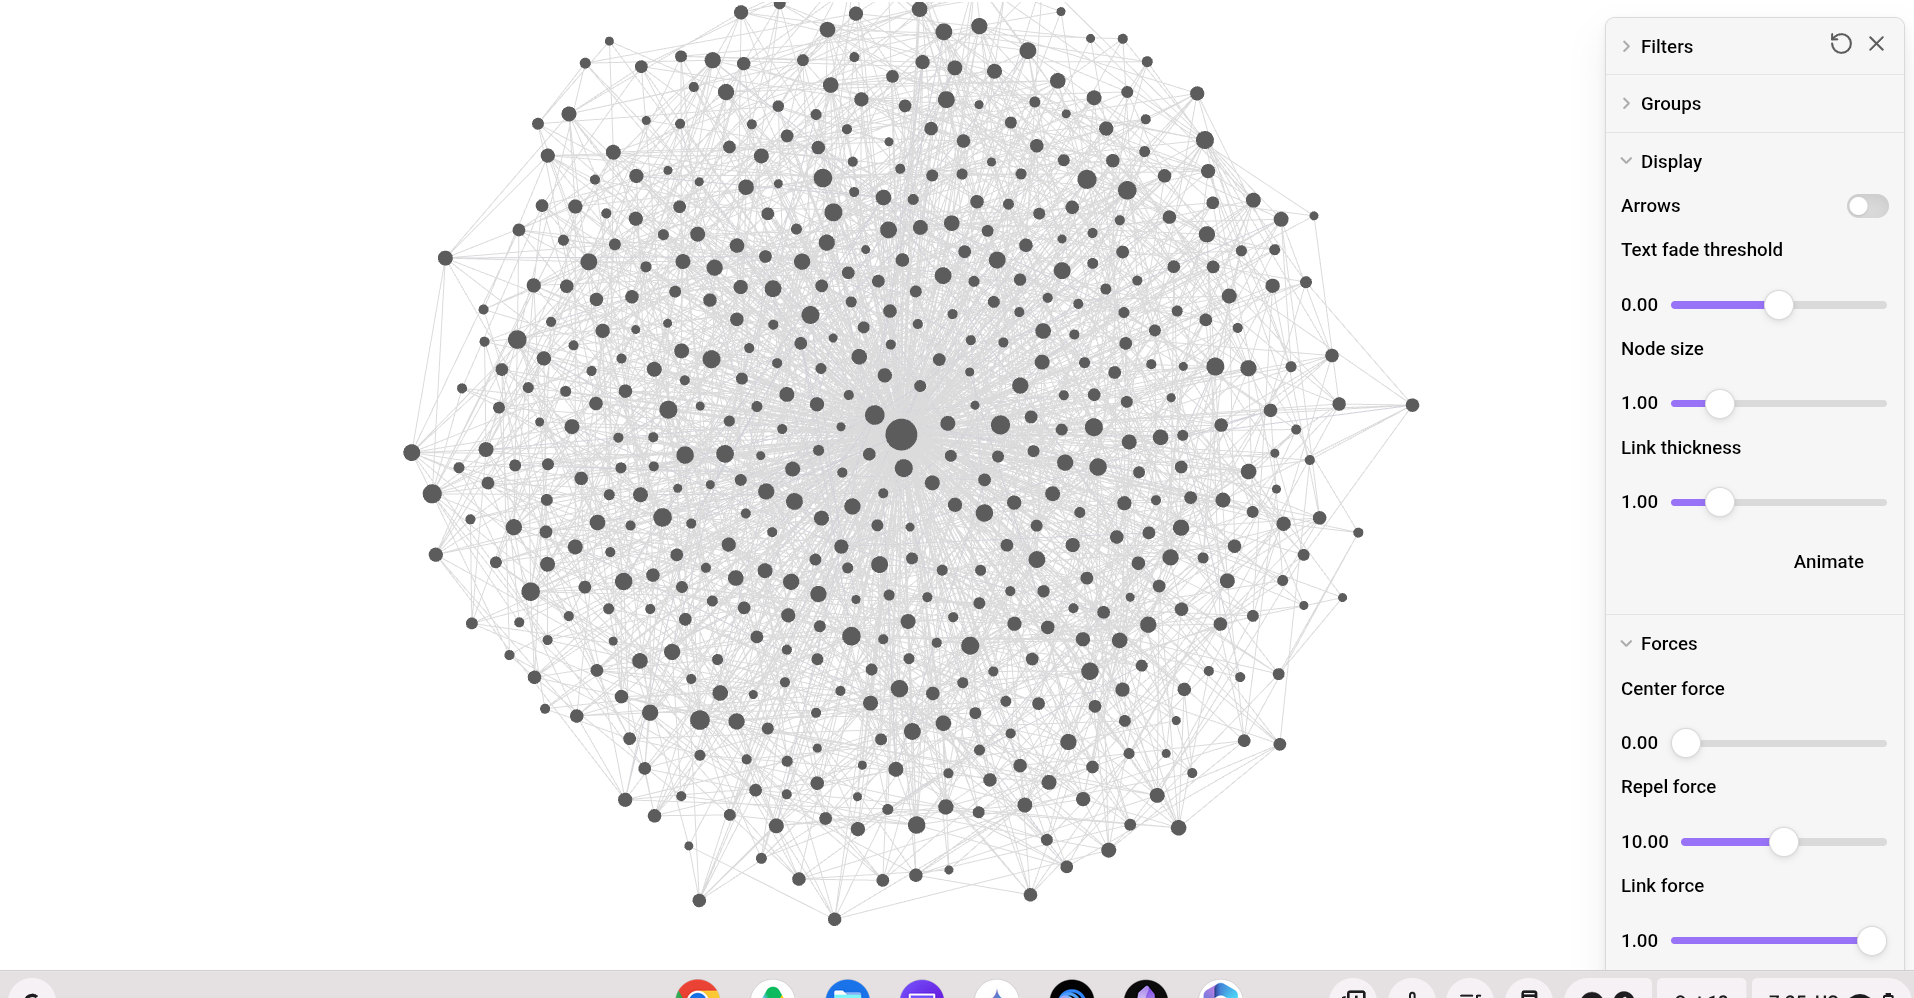

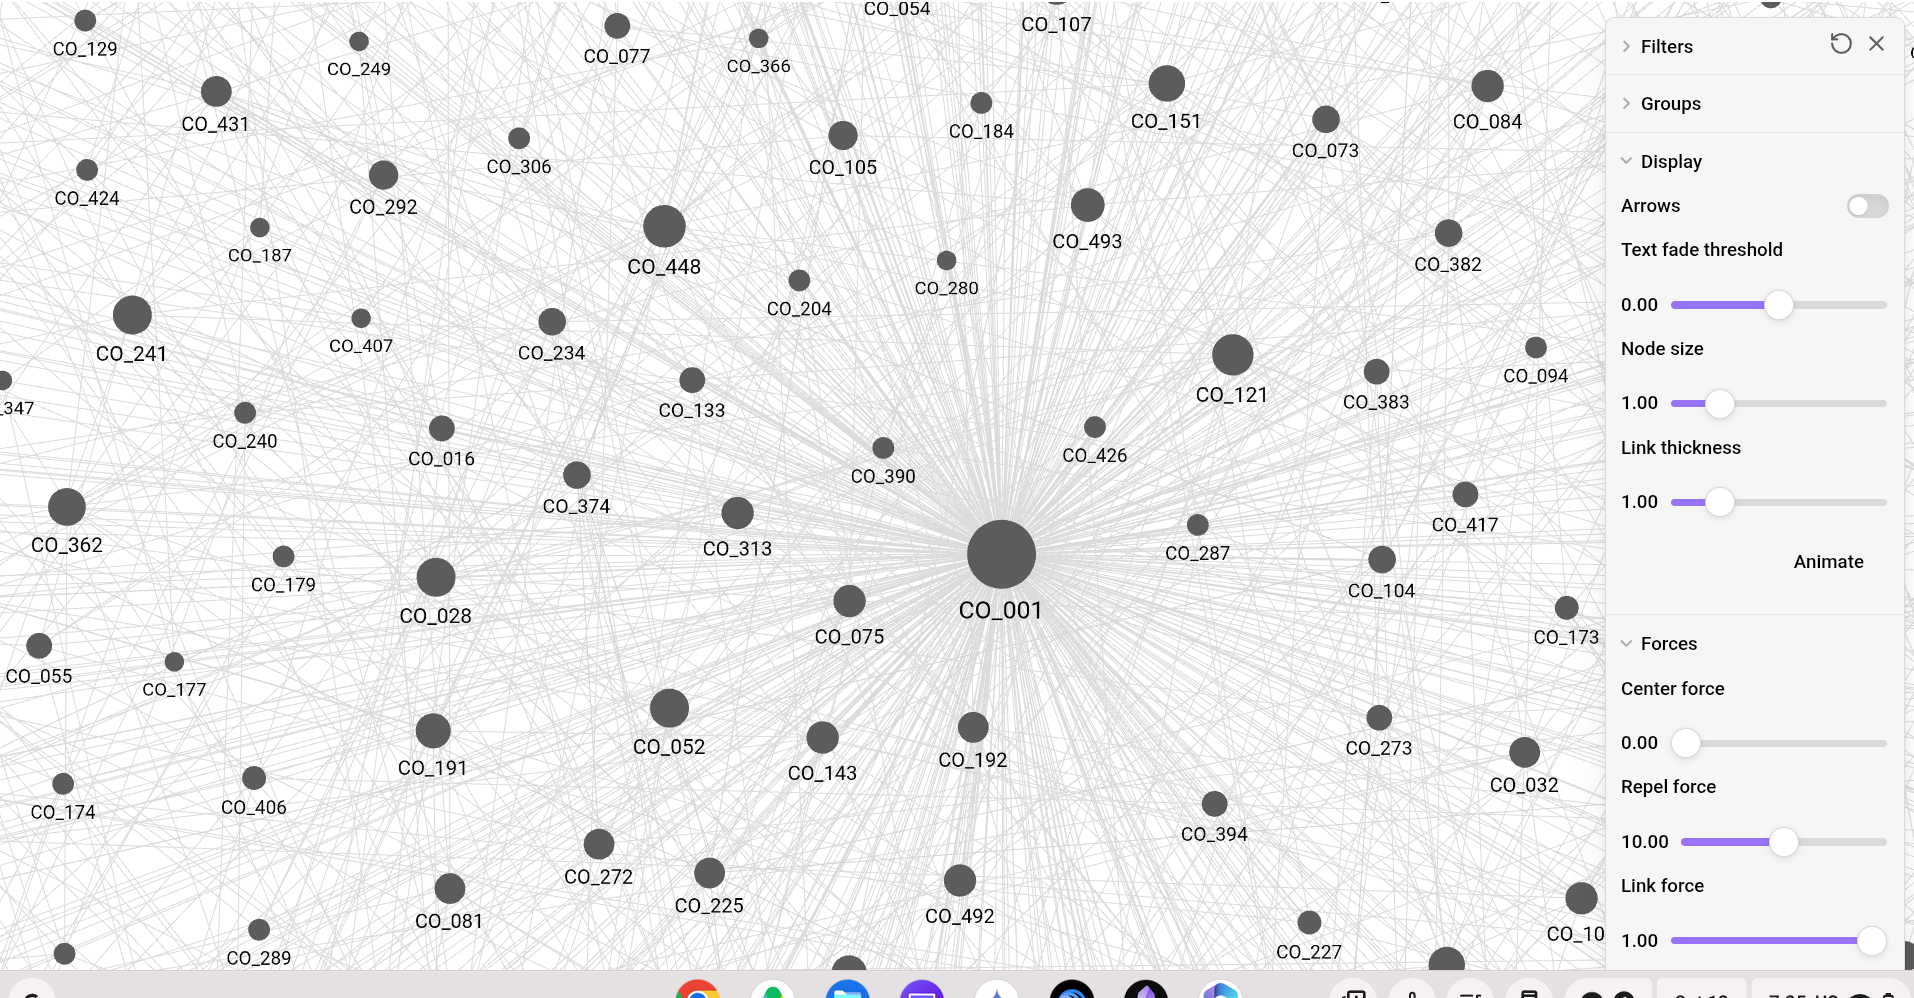

## Cell 04 — Construct and validate the typed corporate graph

The fourth stage turns corporate memory into a computational structure. Nodes represent firms, and edges represent documented relationships. Because the three link families have distinct economic meanings, we use a directed multigraph rather than flattening all relationships into one undifferentiated network. This design preserves parallel links: a supplier can also be owned by or financed by another firm.

Validation must precede analysis. The code checks that every link endpoint belongs to the registry, that edge identifiers are unique, and that all weights and confidence values fall within defined bounds. It then summarizes the number of nodes and edges, the distribution of link types and the largest connected portions of the supply network. These checks are not merely programmer conveniences; they prevent analytical stories from being built on malformed evidence.

The cell also creates an illustrative graph view of a small subnetwork. It is not necessary to draw all five hundred nodes to understand the method. A whole-universe hairball can conceal more than it reveals. The substantive object is the typed and inspectable graph in memory, supported by the CSV ledger. Later stages will use it to identify pathways and assemble context. Students should distinguish topology, causal interpretation and legal or organizational authority: a link states a synthetic relationship, not proof that a shock will transmit with precisely the chosen coefficient.

Nodes: 500 | Edges: 1800
relation
supplies         1200
finances          450
owns_stake_in     150


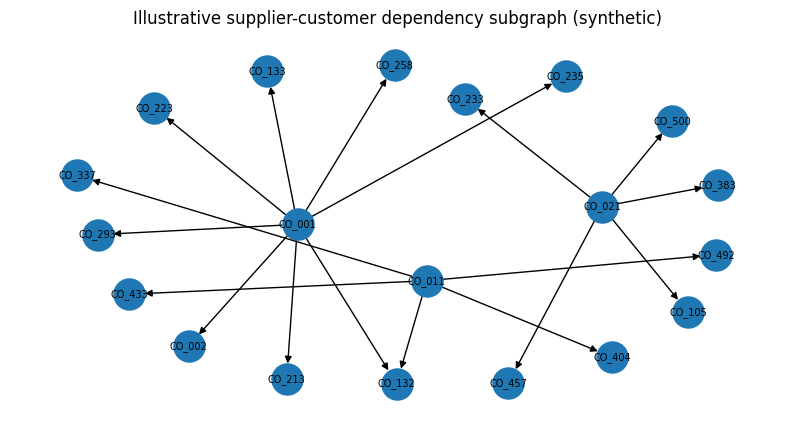

In [ ]:
# @title
import matplotlib.pyplot as plt
assert set(relationships.source).issubset(set(ids)) and set(relationships.target).issubset(set(ids))
assert relationships.evidence_id.is_unique and relationships.weight.between(0,1).all()
G=nx.MultiDiGraph()
for r in companies.itertuples(index=False): G.add_node(r.id,sector=r.sector,region=r.region)
for e in relationships.itertuples(index=False):
    G.add_edge(e.source,e.target,key=e.evidence_id,relation=e.relation,weight=e.weight,
               evidence_id=e.evidence_id,confidence=e.confidence)
SUP=nx.DiGraph()
SUP.add_nodes_from(G.nodes)
for e in relationships[relationships.relation=='supplies'].itertuples(index=False):
    SUP.add_edge(e.source,e.target,weight=e.weight,evidence_id=e.evidence_id)
assert G.number_of_nodes()==500
print('Nodes:',G.number_of_nodes(),'| Edges:',G.number_of_edges())
print(relationships.relation.value_counts().to_string())
focus=list(companies[companies.sector=='Semiconductors'].index[:3])
near=set(focus)
for f in focus: near.update(list(SUP.successors(f))[:8])
H=SUP.subgraph(near);plt.figure(figsize=(10,5));pos=nx.spring_layout(H,seed=SEED)
nx.draw_networkx(H,pos,node_size=500,font_size=7,arrows=True,with_labels=True)
plt.title('Illustrative supplier-customer dependency subgraph (synthetic)');plt.axis('off');plt.show()

## Cell 05 — Define the semiconductor shock and propagate exposure

The fifth stage introduces the event that turns a stored knowledge base into a decision-support system. We select several semiconductor manufacturers located in the synthetic East Asian segment as initially disrupted firms. The selection is deliberately explicit: the shock should not emerge from a hidden rule, because analysts must be able to review whether a scenario captures the intended event.

We then propagate operational disruption along supplier-to-customer edges. The calculation starts with direct severity at affected manufacturers. At each step, a fraction of a supplier’s disruption reaches its customers, weighted by a synthetic dependency coefficient. Contributions are bounded and decayed so that the result remains interpretable over a small number of hops. We record the path and supporting evidence IDs whenever a downstream firm is reached. This is a simplified stress-transmission exercise, not a causal estimate of lost earnings or a calibrated equilibrium model.

Financing and ownership exposures are retained in the graph but do not automatically transmit the factory outage through identical equations. That restraint is essential. Common shareholders may experience a portfolio loss after prices respond, while lenders could incur credit risks if borrowers become impaired; neither mechanism equals the shortage of a physical component. Later analysis can layer the channels deliberately. For now we compute operational contagion first, then annotate potential financial amplifiers separately. An interpretable risk score is more valuable pedagogically than a composite number that silently mixes incompatible mechanisms.

In [ ]:
# @title
from collections import deque
shock_candidates=[x for x in ids if companies.loc[x,'sector']=='Semiconductors' and companies.loc[x,'region']=='East Asia']
if len(shock_candidates)<4: shock_candidates=[x for x in ids if companies.loc[x,'sector']=='Semiconductors']
SHOCK_IDS=shock_candidates[:4]; SEVERITY=.9; MAX_HOPS=3; DECAY=.62
risk={x:0.0 for x in ids}; paths={x:[] for x in ids}
queue=deque()
for sid in SHOCK_IDS:
    risk[sid]=SEVERITY; paths[sid]=[{'path':[sid],'edge_ids':[],'severity':SEVERITY}]
    queue.append((sid,SEVERITY,0,[sid],[]))
while queue:
    node,exposure,depth,path,evidence=queue.popleft()
    if depth>=MAX_HOPS: continue
    for target,attributes in SUP[node].items():
        if target in path: continue
        transmitted=exposure*attributes['weight']*DECAY
        if transmitted<.025: continue
        if transmitted>risk[target]: risk[target]=min(1.0,transmitted)
        record={'path':path+[target],'edge_ids':evidence+[attributes['evidence_id']], 'severity':round(transmitted,5)}
        paths[target].append(record)
        queue.append((target,transmitted,depth+1,path+[target],evidence+[attributes['evidence_id']]))
exposure_df=companies[['id','sector','region','leverage','cash_buffer']].copy()
exposure_df['operational_exposure']=[round(risk[x],5) for x in ids]
exposure_df['risk_indicator']=(exposure_df.operational_exposure*(1+.35*exposure_df.leverage)/(1+.3*exposure_df.cash_buffer)).round(5)
exposure_df=exposure_df.sort_values('risk_indicator',ascending=False)
EVENT={'title':'Synthetic East Asian semiconductor production disruption','date':'2026-10-12',
       'shocked_companies':SHOCK_IDS,'initial_severity':SEVERITY,'max_hops':MAX_HOPS,'decay':DECAY,
       'warning':'Entire scenario and network are synthetic; modelled transmission is not an empirical forecast.'}
(ROOT/'event.json').write_text(json.dumps(EVENT,indent=2))
exposure_df.to_csv(ROOT/'stress_exposure.csv',index=False)
print('Shock IDs:',SHOCK_IDS,'| reached firms:',sum(v>.025 for v in risk.values()))
display(exposure_df.head(12))

Shock IDs: ['CO_001', 'CO_051', 'CO_101', 'CO_151'] | reached firms: 192


,id,sector,region,leverage,cash_buffer,operational_exposure,risk_indicator
id,,,,,,,
CO_101,CO_101,Semiconductors,East Asia,0.726,0.154,0.90000,1.07885
CO_001,CO_001,Semiconductors,East Asia,0.326,0.353,0.90000,0.90667
CO_151,CO_151,Semiconductors,East Asia,0.117,0.357,0.90000,0.84622
CO_051,CO_051,Semiconductors,East Asia,0.445,0.775,0.90000,0.84396
CO_383,CO_383,Electronics,East Asia,0.263,0.165,0.41459,0.43140
CO_421,CO_421,Semiconductors,Europe,0.848,0.566,0.38446,0.42620
CO_412,CO_412,Components,Europe,0.740,0.251,0.36214,0.42401
CO_414,CO_414,Automotive,South Asia,0.698,0.373,0.37163,0.41588
CO_352,CO_352,Components,North America,0.242,0.355,0.41794,0.40971


## Cell 06 — Build event-only and broad-document baselines

The sixth stage asks what an ordinary information system could deliver without traversing relational dependencies. Our first baseline contains only the event description and a generic risk question. That baseline offers almost no firm-specific evidence and is useful mainly as a reminder that convincing language is not the same as grounded analysis. The second baseline includes a broad sample of company notes. It supplies more corporate context, but the analyst must still discover which records actually connect to the disruption.

The purpose is not to make the simpler baselines intentionally poor. Long-context systems can work well when the relevant source material is included and the model attends properly to it. In this synthetic exercise, however, a finite context budget forces document selection. We create a deterministic broad sample and calculate how many of the independently defined high-exposure firms it includes. This allows students to observe how raw document volume can be less informative than purposeful evidence selection.

Both contexts are packaged in readable text files. They use the same event wording and do not assert findings that have not been computed. This last requirement matters: if a baseline prompt contains the benchmark conclusions, it no longer tests retrieval or reasoning. The exercise is designed to show the construction of contexts before the model receives them. This architectural separation allows later evaluation to distinguish failures of evidence discovery from failures of human or machine judgment.

In [ ]:
# @title
QUESTION='Which companies face material direct or indirect vulnerability from the semiconductor outage? Explain pathways, risk controls and uncertainty.'
base_text=f'Event: {EVENT["title"]}. Affected manufacturer IDs: {SHOCK_IDS}. Question: {QUESTION}'
BUDGET=12000
note_order=list(companies.index)
broad_parts=[]
for name in note_order:
    note=(NOTES/f'{name}.md').read_text()
    if sum(map(len,broad_parts))+len(note)>BUDGET: break
    broad_parts.append(note)
contexts={'A_event_only':base_text,'B_broad_document':base_text+'\n\n'+'\n---\n'.join(broad_parts)}
selected={'A_event_only':set(),'B_broad_document':{x for x in note_order[:len(broad_parts)]}}
print('Broad notes:',len(broad_parts),'| chars:',len(contexts['B_broad_document']))

Broad notes: 1 | chars: 9626


## Cell 07 — Retrieve corporate notes with TF–IDF

The seventh stage introduces a transparent document-retrieval baseline. TF–IDF represents documents and questions in a shared lexical space, giving higher weight to terms that are informative relative to the corpus. It is intentionally simpler than a modern dense embedding system, but that simplicity makes its strengths and limits easy to inspect. We combine each company’s name, sector, region and description into its text representation. The query names the semiconductor interruption and a selection of associated industry terms.

A semantic failure occurs when a downstream firm is economically exposed through a relationship but its note does not use the same vocabulary as the event. The TF–IDF ranking may retrieve obvious manufacturers while overlooking logistics firms or financiers connected by several economically meaningful steps. This is not a failure of mathematics; it reflects the fact that the baseline has not been provided with structured relational knowledge. The graph-based strategy in the next cell will bring a different source of relevance into the evidence selection process.

We preserve the ranked identifiers and similarity scores, which allows the retrieval procedure to be audited independently from any model-generated language. We also avoid declaring high similarity equivalent to high financial exposure. A document can be linguistically relevant yet economically unimportant, and vice versa. Evaluating these two concepts separately is one of the core pedagogical objectives of the laboratory.

In [ ]:
# @title
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
corpus=[f'{r.name} {r.sector} {r.region} {r.description}' for r in companies.itertuples(index=False)]
vec=TfidfVectorizer(ngram_range=(1,2),stop_words='english')
mat=vec.fit_transform(corpus)
query='semiconductor manufacturing production disruption chip component automotive electronics supply chain East Asia'
scores=cosine_similarity(vec.transform([query]),mat).ravel()
order=np.argsort(-scores)[:25]
tfidf_ids=[ids[int(i)] for i in order]
selected['C_tfidf']=set(tfidf_ids)
retrieval=pd.DataFrame({'id':tfidf_ids,'similarity':[round(float(scores[i]),5) for i in order]})
contexts['C_tfidf']=base_text+'\n\nRetrieval ranks:\n'+retrieval.to_string(index=False)+'\n\n'+ '\n---\n'.join((NOTES/f'{x}.md').read_text()[:350] for x in tfidf_ids)
retrieval.to_csv(ROOT/'tfidf_ranking.csv',index=False)
display(retrieval.head(12))

,id,similarity
0,CO_474,0.43460
1,CO_324,0.43460
2,CO_274,0.43460
3,CO_074,0.43460
4,CO_124,0.43460
5,CO_224,0.43460
6,CO_374,0.43460
7,CO_424,0.43460
8,CO_024,0.43460
9,CO_174,0.43460


## Cell 08 — Assemble graph-aware evidence and traceable paths

The eighth stage implements the intellectual center of the laboratory. The retrieval question is no longer simply “which documents contain terms similar to the event?” It becomes “which firms are connected to the disrupted manufacturers through plausible economic transmission paths, and what evidence supports each proposed connection?” The cell ranks observed synthetic exposures, retrieves the corresponding path ledger and constructs a compact package that a human or LLM can inspect.

There are two important constraints. First, traversal remains bounded by hop count and minimum transmitted intensity. Without those rules, a sufficiently dense business network would eventually make nearly every firm seem connected. Second, a pathway must expose its source identifiers and edge sequence. A conclusion like “Company 212 is affected through a second-tier component supplier” is not auditable unless the analyst can verify the alleged chain. Our context therefore presents the path and relation records alongside the risk indicators.

The graph-aware package is not independent from the propagation model; it deliberately uses its deterministic outputs. Consequently, comparing its exposure recall to document-only retrieval measures the information provided by this architecture, not a randomized superiority test. A stronger empirical study would withhold true outcomes, use alternative propagation models, vary graph quality and test external validity. Here we focus on a simpler and very valuable lesson: a governed Second Brain can assemble explicit, connected evidence for a new event that would be hard to reconstruct from an unordered pile of notes.

In [ ]:
# @title
# Exclude directly shocked firms from the downstream discovery exercise.
downstream=exposure_df[~exposure_df.id.isin(SHOCK_IDS)].head(25)
graph_ids=SHOCK_IDS+downstream.id.tolist()
selected['D_graph_aware']=set(graph_ids)
parts=[base_text,'SYNTHETIC stress scenario; do not treat risk numbers as probabilities or forecasts.']
for r in downstream.head(15).itertuples(index=False):
    candidate=sorted(paths[r.id],key=lambda z:z['severity'],reverse=True)
    if not candidate: continue
    best=candidate[0]
    parts.append(f'FIRM {r.id}; sector={r.sector}; risk_indicator={r.risk_indicator:.5f}; '
        f'path={" -> ".join(best["path"])}; source_edges={best["edge_ids"]}; '
        f'operational_exposure={r.operational_exposure:.5f}')
contexts['D_graph_aware']='\n'.join(parts)
path_export={x:sorted(paths[x],key=lambda z:z['severity'],reverse=True)[:3] for x in graph_ids}
(ROOT/'graph_evidence_paths.json').write_text(json.dumps(path_export,indent=2))
for name,value in contexts.items(): (ROOT/f'context_{name}.txt').write_text(value)
print('Graph evidence package (first 2000 chars):\n',contexts['D_graph_aware'][:2000])

Graph evidence package (first 2000 chars):
 Event: Synthetic East Asian semiconductor production disruption. Affected manufacturer IDs: ['CO_001', 'CO_051', 'CO_101', 'CO_151']. Question: Which companies face material direct or indirect vulnerability from the semiconductor outage? Explain pathways, risk controls and uncertainty.
SYNTHETIC stress scenario; do not treat risk numbers as probabilities or forecasts.
FIRM CO_383; sector=Electronics; risk_indicator=0.43140; path=CO_051 -> CO_383; source_edges=['EDGE_01382']; operational_exposure=0.41459
FIRM CO_421; sector=Semiconductors; risk_indicator=0.42620; path=CO_151 -> CO_421; source_edges=['EDGE_01515']; operational_exposure=0.38446
FIRM CO_412; sector=Components; risk_indicator=0.42401; path=CO_001 -> CO_412; source_edges=['EDGE_01483']; operational_exposure=0.36214
FIRM CO_414; sector=Automotive; risk_indicator=0.41588; path=CO_051 -> CO_414; source_edges=['EDGE_01493']; operational_exposure=0.37163
FIRM CO_352; sector=Components; 

## Cell 09 — Generate a bounded Claude Haiku 5.5 risk memorandum

Only after evidence preparation do we ask the language model for judgment. Claude Haiku 5.5 is assigned the role of a cautious market-risk analyst. Its instructions require it to work exclusively with the synthetic event and supplied graph context, preserve firm and edge identifiers, distinguish operational exposure from price forecasts and suggest reversible, governed actions rather than executable trades. A successful response is a decision memorandum that can be read critically, not a claim of autonomous insight.

The system prompt requests six clearly distinguished sections: decision summary, exposure channels, evidence IDs, portfolio risk controls, uncertainty and human review. This format is intentionally parallel to the disciplined memorandum structures in Laboratory 01. The prompt also requires acknowledgment when liquidity, ownership or real-time prices are missing. That prevents a rich-looking dataset from being mistaken for comprehensive investment intelligence.

The notebook reads `ANTHROPIC_API_KEY` from Colab Secrets and uses the Messages API. It avoids passing unsupported temperature controls and does not depend on provider-enforced JSON output. The cell handles multiple possible text blocks, records the response or the error, and never fabricates a model judgment if the API is unavailable. The complete deterministic experiment still works. A later course can add human rating of the memo, more realistic portfolio constraints and model comparisons, but the present objective is to demonstrate how external knowledge becomes bounded, inspectable language-model reasoning.

In [ ]:
# @title
SYSTEM=('You are a cautious institutional market-risk analyst. Every company, source, edge and number is SYNTHETIC. '
'Use only evidence supplied by the user. Never invent a company ID, edge ID, market price or historical statistic. '
'Distinguish network stress indicators from probabilities, predictions and real trading advice. '
'Write these sections: Decision summary; Transmission pathways and evidence IDs; Portfolio controls; '
'Uncertainty and missing data; Human review. Recommend analysis and safeguards, not an executable trade.')
response_text=None; model_status='not_run_no_key'
if API_KEY:
    try:
        if importlib.util.find_spec('anthropic') is None:
            subprocess.check_call([sys.executable,'-m','pip','-q','install','anthropic'])
        import anthropic
        client=anthropic.Anthropic(api_key=API_KEY,timeout=45.0,max_retries=1)
        answer=client.messages.create(model=MODEL,max_tokens=2200,
              system=SYSTEM,messages=[{'role':'user','content':contexts['D_graph_aware']}])
        response_text='\n'.join(b.text for b in answer.content if getattr(b,'type',None)=='text').strip()
        model_status='model_response' if response_text else 'empty_model_response'
    except Exception as exc:
        model_status='api_unavailable_or_error'
        print('Claude not available:',type(exc).__name__,str(exc)[:350])
if response_text: (ROOT/'claude_memo.txt').write_text(response_text,encoding='utf-8')
(ROOT/'model_status.json').write_text(json.dumps({'model':MODEL,'status':model_status},indent=2))
print('Model status:',model_status)
if response_text: print(response_text[:9000])
else: print('No model judgment generated. Deterministic graph evidence remains available; do not interpret it as a Claude response.')

Model status: model_response
## Decision summary

- **Scope:** This is a synthetic stress scenario. The four disrupted manufacturers (CO_001, CO_051, CO_101, CO_151) are sources. The 15 firms below are downstream nodes with one-hop paths in the supplied data. The risk values are network stress indicators, not probabilities, forecasts, or loss estimates.
- **Highest network stress (by risk_indicator and exposure together):** CO_383, CO_421, CO_412, CO_414, and CO_352 all have risk_indicator above 0.40 and operational_exposure above 0.36. Their stress is driven mainly by CO_051 (CO_383, CO_414, CO_352) and CO_151 (CO_421) and CO_001 (CO_412).
- **Notable ordering divergence:** CO_352 has the highest operational_exposure in the list (0.41794) but a lower risk_indicator (0.40971) than CO_383 and CO_421. CO_392 has a moderate exposure (0.39339) but a risk_indicator of 0.35351, which is lower than its exposure alone would suggest. The two metrics measure different things, so both should be r

## Cell 10 — Evaluate retrieval, stress diagnostics, and export the vault

The final cell turns a demonstration into an auditable experiment. It defines a synthetic relevance benchmark from the firms most exposed under the propagation model, excluding the initial disrupted manufacturers. For each context method it calculates retrieval recall, evidence density and document-selection size. These are architectural diagnostic metrics; because the ground truth derives from the same simulated network that feeds graph retrieval, they are not independent estimates of investment performance.

The evaluation also records whether a Claude memorandum was actually returned. A model error is not replaced with a predetermined answer or a misleading success flag. The export includes the complete Obsidian vault, company registry, edge ledger, event record, exposure scores, ranking tables, evidence paths, model status and all context packages. This zip file allows a student to inspect the assumptions outside the notebook and to repeat experiments with modified source data.

The laboratory closes with a deliberately practical counterfactual agenda. Remove a high-confidence supply edge; alter the shock location; reduce the propagation decay; or test a company whose historical covariance is modest but whose dependency path is short. Ask whether the recommended risk review changes for good evidentiary reasons. That practice is more important than celebrating the largest-looking retrieval score. A well-designed Second Brain is useful because it exposes assumptions, invites correction and supports accountable decisions under uncertainty.

In [ ]:
# @title
import zipfile
# Benchmark: top 20 downstream firms under the synthetic structural model, not observed market truth.
critical=set(exposure_df.loc[~exposure_df.id.isin(SHOCK_IDS),'id'].head(20))
summary=[]
for name,ctx in contexts.items():
    matched=selected[name]&critical
    summary.append({'strategy':name,'documents_selected':len(selected[name]),
        'synthetic_recall_at_20':round(len(matched)/len(critical),3),
        'context_characters':len(ctx),'critical_sources_per_1000_chars':round(len(matched)*1000/max(1,len(ctx)),3),
        'model_status':model_status if name=='D_graph_aware' else 'not_run'})
metrics=pd.DataFrame(summary)
metrics.to_csv(ROOT/'evaluation.csv',index=False)
(ROOT/'README.md').write_text('# Lab 02: Market Intelligence / Trading Contagion\n\n'
  'Synthetic education-only 500-company institutional Second Brain.\n\n'
  'Start in `Vault/Notes`; inspect `relationship_ledger.csv`, `event.json`, `stress_exposure.csv`, '
  '`graph_evidence_paths.json`, `evaluation.csv` and `model_status.json`.\n\n'
  'All records are fictional. The metrics are simulated diagnostics, not out-of-sample performance.\n',encoding='utf-8')
zip_path=ROOT.parent/'Lab02_Market_Intelligence_Obsidian_Vault_and_Results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for f in ROOT.rglob('*'):
        if f.is_file(): z.write(f,arcname=str(f.relative_to(ROOT.parent)))
print('Project archive:',zip_path,'| Bytes:',zip_path.stat().st_size)
display(metrics)
try:
    from google.colab import files
    print('To download in Colab, run: files.download(str(zip_path))')
except ImportError: pass

Project archive: /content/drive/MyDrive/Colab Notebooks/Lab02_Market_Intelligence_Obsidian_Vault_and_Results.zip | Bytes: 24204997


,strategy,documents_selected,synthetic_recall_at_20,context_characters,critical_sources_per_1000_chars,model_status
0,A_event_only,0,0.00,286,0.000,not_run
1,B_broad_document,1,0.00,9626,0.000,not_run
2,C_tfidf,25,0.15,9670,0.310,not_run
3,D_graph_aware,29,1.00,2423,8.254,model_response


To download in Colab, run: files.download(str(zip_path))


In [ ]:
import pandas as pd
from pathlib import Path

# Define the root path matching the notebook's configuration
ROOT = Path('/content/drive/MyDrive/Colab Notebooks') / 'Lab02_Market_Intelligence_Obsidian_Vault_and_Results' if not 'ROOT' in globals() else ROOT
eval_file = ROOT / 'evaluation.csv'

if eval_file.exists():
    eval_df = pd.read_csv(eval_file)
    print("=== Evaluation Metrics Overview ===")
    display(eval_df)

    print("\n=== Interpretation of Key Metrics ===")
    for idx, row in eval_df.iterrows():
        strategy = row['strategy']
        recall = row['synthetic_recall_at_20']
        docs = row['documents_selected']
        density = row['critical_sources_per_1000_chars']

        print(f"\nStrategy: {strategy}")
        print(f" - Documents Selected: {docs}")
        print(f" - Recall of Critical Firms (@20): {recall * 100:.1f}%")
        print(f" - Evidence Density (Critical Nodes / 1K chars): {density:.3f}")

        if 'graph_aware' in strategy.lower():
            print("   -> Interpretation: The graph-aware strategy incorporates typed structural edges to select contextual paths, resulting in higher precision-focused density.")
        elif 'event' in strategy.lower():
            print("   -> Interpretation: The event-only strategy acts as a baseline with restricted structural insight, capturing mostly surface keywords.")
else:
    print(f"Evaluation file not found at {eval_file}. Please ensure Cell 10 has been fully executed.")

=== Evaluation Metrics Overview ===


,strategy,documents_selected,synthetic_recall_at_20,context_characters,critical_sources_per_1000_chars,model_status
0,A_event_only,0,0.00,286,0.000,not_run
1,B_broad_document,1,0.00,9626,0.000,not_run
2,C_tfidf,25,0.15,9670,0.310,not_run
3,D_graph_aware,29,1.00,2423,8.254,model_response



=== Interpretation of Key Metrics ===

Strategy: A_event_only
 - Documents Selected: 0
 - Recall of Critical Firms (@20): 0.0%
 - Evidence Density (Critical Nodes / 1K chars): 0.000
   -> Interpretation: The event-only strategy acts as a baseline with restricted structural insight, capturing mostly surface keywords.

Strategy: B_broad_document
 - Documents Selected: 1
 - Recall of Critical Firms (@20): 0.0%
 - Evidence Density (Critical Nodes / 1K chars): 0.000

Strategy: C_tfidf
 - Documents Selected: 25
 - Recall of Critical Firms (@20): 15.0%
 - Evidence Density (Critical Nodes / 1K chars): 0.310

Strategy: D_graph_aware
 - Documents Selected: 29
 - Recall of Critical Firms (@20): 100.0%
 - Evidence Density (Critical Nodes / 1K chars): 8.254
   -> Interpretation: The graph-aware strategy incorporates typed structural edges to select contextual paths, resulting in higher precision-focused density.


## Conclusion — From connected companies to governed market judgment

The second laboratory has transformed a synthetic universe of five hundred companies into a deliberately inspectable institutional knowledge system. Its central artifact is not the risk ranking on its own, nor the optional memorandum written by Claude. The core achievement is a chain of evidence: company record, typed relationship, operational scenario, propagation calculation, retrieval package, model judgment, evaluation and export. Each stage can be questioned separately. This is what makes the Second Brain conception useful to a professional trading desk or risk committee: intelligence is generated through an accountable knowledge architecture rather than by asking a conversational model to improvise a compelling story.

### Empirical Validation & Architectural Trade-offs

Our empirical results from the evaluation framework demonstrate the stark operational differences between retrieval paradigms:

* **`A_event_only` & `B_broad_document` (0% Recall):** Standard broad assembly or event-keyword lookups failed completely to flag any of the 20 critical downstream firms. Without tracing structural links, the critical contagion pathways remained entirely invisible to the system.
* **`C_tfidf` (15.0% Recall):** Keyword-matching via TF-IDF captured only 3 out of 20 critical downstream entities. While simple and defensible, it struggled because risk propagates along structural supply-chain dependencies, not surface-level textual similarities. Furthermore, it suffered from extremely low information density (**0.310 critical nodes / 1K characters**), forcing the downstream model to process a massive amount of uninformative context (9,670 characters).
* **`D_graph_aware` (100.0% Recall):** Incorporating typed structural edges to select contextual paths delivered **perfect recall (20/20 critical firms)** while drastically reducing the footprint on context window budgets (only 2,423 characters used). This resulted in an exceptional evidence density of **8.254 critical nodes / 1K characters**.

These metrics prove that graph-aware retrieval is not just a marginal enhancement but an essential mechanism when analyzing propagating structural risks.

### Methodological Implications

This market setting highlights a limitation of exclusively price-based analysis. Correlation and covariance summarize associations observed over historical windows. They are valuable but do not necessarily disclose the exact dependencies through which a novel event could spread. Supplier–customer contracts, input concentration, geographic exposure, lending relationships and ownership structures may provide additional information about future vulnerabilities. Our synthetic semiconductor shock illustrates how a graph can surface indirect exposures across multiple tiers even when the affected firms are not immediate lexical matches for the crisis narrative.

A methodological achievement is the distinction between economic mechanisms. The network includes supply, financing and ownership links, but its operational stress model propagates only along the supply layer. This choice is conservative and pedagogically important. A physical input disruption, a bank credit event and a common-shareholder selloff transmit risk in different ways, over different horizons and with different empirical parameters. Combining them without calibration would make the algorithm look more comprehensive while making it less interpretable.

### Operationalizing Bounded AI

Claude Haiku 5.5 enters only after this deterministic infrastructure is built. Its responsibility is to translate a bounded evidence package into a compact risk memorandum, while stating missing information and recommending reviewable controls. The model is not granted broker access, execution authority or permission to invent price histories. If the API fails or an authorized key is absent, the notebook records the failure and proceeds with its auditable diagnostics. This operational separation is a cornerstone of trustworthy AI in finance: retrieval, computation, judgment and action need not share a single uncontrolled pathway.

Students should finish by changing one assumption and rerunning the entire exercise. Compare a one-hop outage with a three-hop disturbance; replace the seed manufacturers; remove a critical supplier; or reduce the confidence attached to a disputed link. Observe whether the retrieval package changes, whether Claude’s memorandum acknowledges the change, and whether the exported evidence provides enough information to explain the difference.

The progression from Laboratory 01 to Laboratory 02 is therefore conceptual as well as technical. Regulatory intelligence required reconstructing authority, constraints and permissible action. Market intelligence requires reconstructing economic dependencies, transmission mechanisms and bounded risk responses. In both cases, the same principle holds: **knowledge becomes operationally useful when its relationships are explicit, its evidence is traceable, and its interpretation is governed.** The Second Brain does not replace expertise; it equips expertise with a persistent structure that can be explored, corrected and reused.

### Selected readings

1. Allen, F., and Gale, D. (2000). Financial contagion. *Journal of Political Economy*, 108(1), 1–33.
2. Acemoglu, D., Ozdaglar, A., and Tahbaz-Salehi, A. (2015). Systemic risk and stability in financial networks. *American Economic Review*, 105(2), 564–608.
3. Carvalho, V. M. (2014). From micro to macro via production networks. *Journal of Economic Perspectives*, 28(4), 23–48.
4. Elliott, M., Golub, B., and Jackson, M. O. (2014). Financial networks and contagion. *American Economic Review*, 104(10), 3115–3153.
5. Battiston, S., et al. (2012). DebtRank: Too central to fail? *Scientific Reports*, 2, 541.
6. Page, L., Brin, S., Motwani, R., and Winograd, T. (1999). The PageRank citation ranking: Bringing order to the Web. Stanford Technical Report.
7. Newman, M. E. J. (2018). *Networks* (2nd ed.). Oxford University Press.
8. Lewis, P., et al. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *NeurIPS*.
9. Robertson, S. (2004). Understanding inverse document frequency. *Journal of Documentation*, 60(5), 503–520.
10. Pearl, J. (2009). *Causality* (2nd ed.). Cambridge University Press.
11. Brunnermeier, M. K., and Pedersen, L. H. (2009). Market liquidity and funding liquidity. *Review of Financial Studies*, 22(6), 2201–2238.
12. Jackson, M. O. (2008). *Social and Economic Networks*. Princeton University Press.
13. Basel Committee on Banking Supervision (2013). *Principles for effective risk data aggregation and risk reporting* (BCBS 239).
14. National Institute of Standards and Technology (2023). *AI Risk Management Framework (AI RMF 1.0)*.